In [4]:
from google.colab import files
uploaded=files.upload()

Saving diabetes.csv to diabetes.csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [7]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.shape

(768, 9)

In [12]:
skewed_cols=['Insulin','DiabetesPedigreeFunction']

for col in skewed_cols:
  df[col]=np.sqrt(df[col])

In [13]:
df.skew()

,0
Pregnancies,0.901674
Glucose,0.173754
BloodPressure,-1.843608
SkinThickness,0.109372
Insulin,0.629955
BMI,-0.428982
DiabetesPedigreeFunction,0.901802
Age,1.129597
Outcome,0.635017


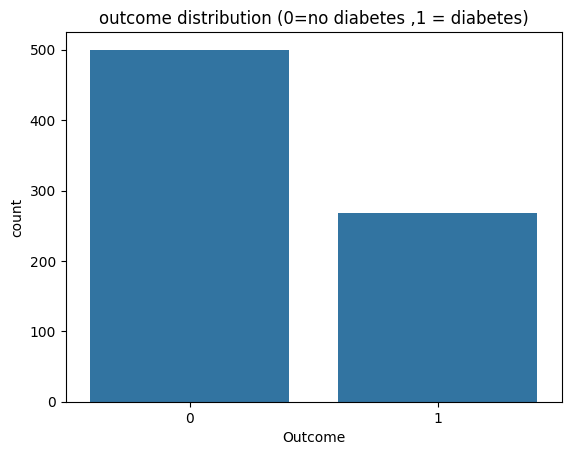

In [14]:
sns.countplot(x='Outcome',data=df)
plt.title("outcome distribution (0=no diabetes ,1 = diabetes)")
plt.show()

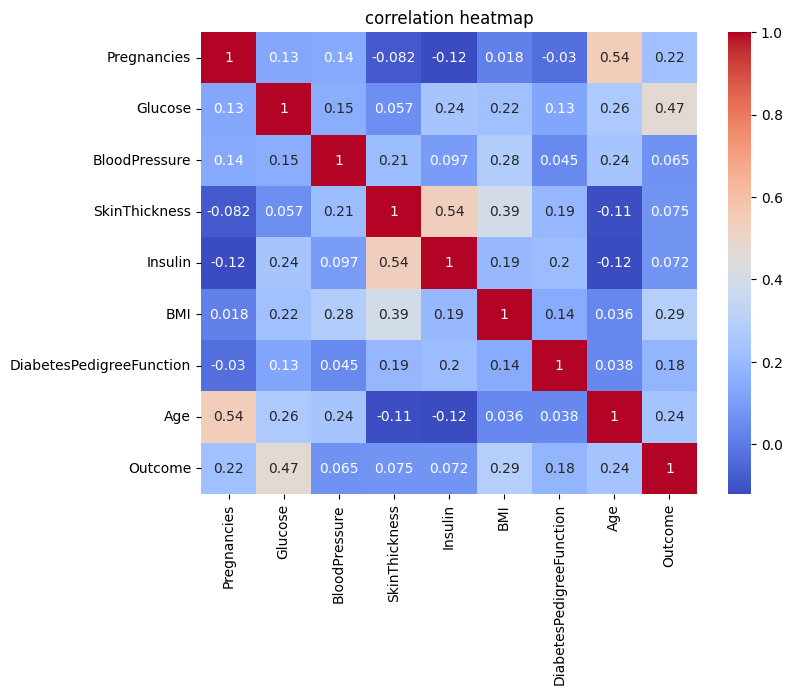

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(),annot=True,cmap=("coolwarm"))
plt.title("correlation heatmap")
plt.show()


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
from sklearn.preprocessing import StandardScaler

Evaluation Metrix

confusion mtrix

TP=true positive
FP=false positive
FN=false negative
TN=true negative

In [17]:
x=df.drop("Outcome",axis=1)
y=df["Outcome"]

In [18]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0.000000,33.6,0.791833,50
1,1,85,66,29,0.000000,26.6,0.592453,31
2,8,183,64,0,0.000000,23.3,0.819756,32
3,1,89,66,23,9.695360,28.1,0.408656,21
4,0,137,40,35,12.961481,43.1,1.512614,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,13.416408,32.9,0.413521,63
764,2,122,70,27,0.000000,36.8,0.583095,27
765,5,121,72,23,10.583005,26.2,0.494975,30
766,1,126,60,0,0.000000,30.1,0.590762,47


In [19]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [21]:
x_train.shape

(537, 8)

In [22]:
x_test.shape

(231, 8)

In [23]:
y_train.shape

(537,)

In [24]:
y_test.shape

(231,)

In [25]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [26]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)

LogisticRegression(max_iter=1000)

In [27]:
y_pred=model.predict(x_test)


In [28]:
print("accuracy:",accuracy_score(y_test,y_pred))
print("\nconfusion matrix:\n",confusion_matrix(y_test,y_pred))
print("\nCLASSIFICATION metrix\n",classification_report(y_test,y_pred))

accuracy: 0.7445887445887446

confusion matrix:
 [[122  29]
 [ 30  50]]

CLASSIFICATION metrix
               precision    recall  f1-score   support

           0       0.80      0.81      0.81       151
           1       0.63      0.62      0.63        80

    accuracy                           0.74       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.74      0.74      0.74       231



In [29]:
#comparison data frame
compare=pd.DataFrame({"actual":y_test,"predicted":y_pred})
compare.head(20)

,actual,predicted
668,0,0
324,0,0
624,0,0
690,0,0
473,0,0
204,0,0
97,0,0
336,0,1
568,0,1
148,0,1
